EOP crossings (first graph, alpha in degrees):
  y = 0.2: alpha = [76.30999606]
  y = 0.4: alpha = [53.36641452]
  y = 0.6: alpha = [38.92302609]
  y = 0.8: alpha = [25.40289682]


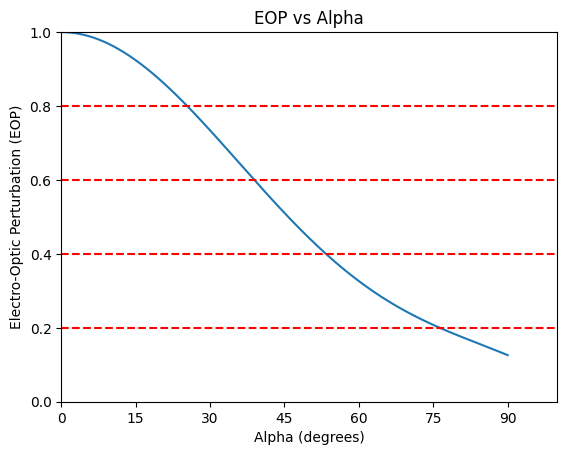


EOP crossings (full range, alpha in degrees):
  y = 0.2: alpha = [-57.58341896  76.31006999]
  y = 0.4: alpha = [-46.15251603  53.3664641 ]
  y = 0.6: alpha = [-35.62760038  38.92304304]
  y = 0.8: alpha = [-24.13605607  25.40282233]


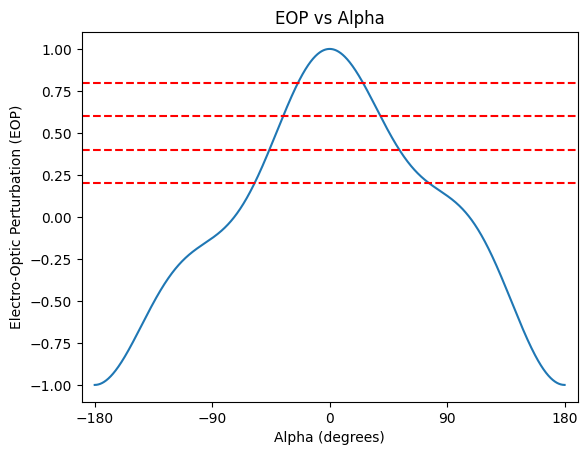

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Constants
e22 = 4.889
e33 = 4.569
r22 = 3.4
r23 = 8.6
r33 = 30.9

def EOP(alpha):
    return np.cos(alpha) ** 3 + (e22/e33) ** 2 * (r22/r33 * np.sin(alpha) + r23/r33 * np.cos(alpha)) * (np.sin(alpha)) ** 2

def find_alpha_for_y(target_y, alpha_vals, y_vals):
    """Find approximate alpha values (in radians) where EOP(alpha) = target_y"""
    roots = []
    for i in range(len(y_vals) - 1):
        if (y_vals[i] - target_y) * (y_vals[i+1] - target_y) < 0:
            # Linear interpolation for better accuracy
            a1, a2 = alpha_vals[i], alpha_vals[i+1]
            y1, y2 = y_vals[i], y_vals[i+1]
            alpha_root = a1 + (target_y - y1) * (a2 - a1) / (y2 - y1)
            roots.append(alpha_root)
    return np.degrees(roots)

# ---------- First graph (0 to 100 degrees) ----------
alpha = np.linspace(0, np.pi/2, 2000)
y = EOP(alpha)

# Thresholds
thresholds = [0.2, 0.4, 0.6, 0.8]

# Find and print results
print("EOP crossings (first graph, alpha in degrees):")
for t in thresholds:
    roots = find_alpha_for_y(t, alpha, y)
    print(f"  y = {t:.1f}: alpha = {roots}")

# Plot
plt.plot(np.degrees(alpha), y)
for t in thresholds:
    plt.axhline(y=t, color='r', linestyle='--')
plt.xlim(0, 100)
plt.ylim(0, 1)
plt.xlabel('Alpha (degrees)')
plt.ylabel('Electro-Optic Perturbation (EOP)')
plt.title('EOP vs Alpha')
plt.xticks(np.arange(0, 91, 15))
plt.savefig("EOP_half_range.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- Second graph (-180 to 180 degrees) ----------
alpha = np.linspace(-np.pi, np.pi, 2000)
y = EOP(alpha)

print("\nEOP crossings (full range, alpha in degrees):")
for t in thresholds:
    roots = find_alpha_for_y(t, alpha, y)
    print(f"  y = {t:.1f}: alpha = {roots}")

plt.plot(np.degrees(alpha), y)
for t in thresholds:
    plt.axhline(y=t, color='r', linestyle='--')
plt.xlim(-190, 190)
plt.xlabel('Alpha (degrees)')
plt.ylabel('Electro-Optic Perturbation (EOP)')
plt.title('EOP vs Alpha')
plt.xticks(np.arange(-180, 181, 90))
plt.savefig("EOP_full_range.png", dpi=300, bbox_inches="tight")
plt.show()
